# Tutorial 5 — time–Cure Superposition (tCS)

Same machinery as [Tutorial 4](./4_time%20temperature%20superposition.ipynb),
but with **cure time** as the state variable instead of temperature. As
the gel cures, the linear viscoelastic spectra
measured at successive cure times are horizontally shifted onto a single
master curve — a construction termed **time–cure superposition (tCS)**,
directly analogous to time–temperature superposition.

:::{seealso}
- Perego, A. *et al.* (2025), *Evaluation of Optimally Windowed Chirp
  Signals in Industrial Rheological Measurements: Method Development and
  Data Processing*, Rheologica Acta.
  DOI: [`10.1007/s00397-025-01511-0`](https://link.springer.com/article/10.1007/s00397-025-01511-0)
  — introduces the time–cure superposition (tCS) workflow used here.
- Lennon, K. R., McKinley, G. H. and Swan, J. W. (2023), *A data-driven
  method for automated data superposition with applications in soft
  matter science*, Data-Centric Engineering **4**, e13 — the
  `AutomatedMasterCurve` algorithm used here.  DOI:
  [`10.1017/dce.2023.3`](https://doi.org/10.1017/dce.2023.3)
  · preprint: [`arXiv:2204.09521`](https://arxiv.org/abs/2204.09521).
- Chambon, F. & Winter, H. H. (1987), *Linear Viscoelasticity at the
  Gel Point of a Crosslinking PDMS with Imbalanced Stoichiometry*,
  J. Rheol. **31**(8), 683–697 — classical gel-point framework.  DOI:
  [`10.1122/1.549955`](https://doi.org/10.1122/1.549955).
:::


In [1]:
import os
import warnings

import matplotlib.pyplot as plt

from hermes_rheo import read_file
from hermes_rheo.file_readers.trios_rheo_txt import TriosRheoReader
from hermes_rheo.transforms.owchirp_analysis import OWChirpAnalysis
from hermes_rheo.transforms.automated_mastercurve import AutomatedMasterCurve

from hermes_rheo.visualization import get_unit, unit_suffix, use_science_style
use_science_style()

warnings.filterwarnings("ignore")  # sklearn convergence warnings

In [2]:
# Get the current directory where the notebook is located
current_dir = os.path.dirname(os.path.abspath("__file__"))  # Use "__file__" to get the notebook's directory

# Construct the relative path
filepath = os.path.join(current_dir, 'tutorial_data', 'tutorial_5', 'owchirp_tcs.txt')

In [3]:
experiment = read_file(
    filepath,
    file_reader=TriosRheoReader,
    create_composite_datasets=True,
)

#### The pipeline is the same as for time-temperature superposition, but in this case, we use time as the state variable. Instead of averaging the step time, we use the first point in the step time measurements

In [4]:
# Run OWChirpAnalysis first (so the OWChirp-derived moduli are exposed on
# a real ExperimentSet), then hand that off to the master-curve shifter.
# Keeping the two steps separate lets us query units from `experiment_owchirp`
# later on for axis labels.
experiment_owchirp = OWChirpAnalysis()(experiment)

mastercurve_complex_modulus = AutomatedMasterCurve(
    state="time",
    state_mode="first point",
    x="angular frequency",
    y="complex modulus",
    vertical_shift=False,
    reverse_data=True,
)(experiment_owchirp)

In [5]:
mastercurve_complex_modulus.change_ref(mastercurve_complex_modulus.states[-1])

In [6]:
a_complex = mastercurve_complex_modulus.hparams[0]
a_complex_uncertainties = mastercurve_complex_modulus.huncertainties[0]

### Visualization


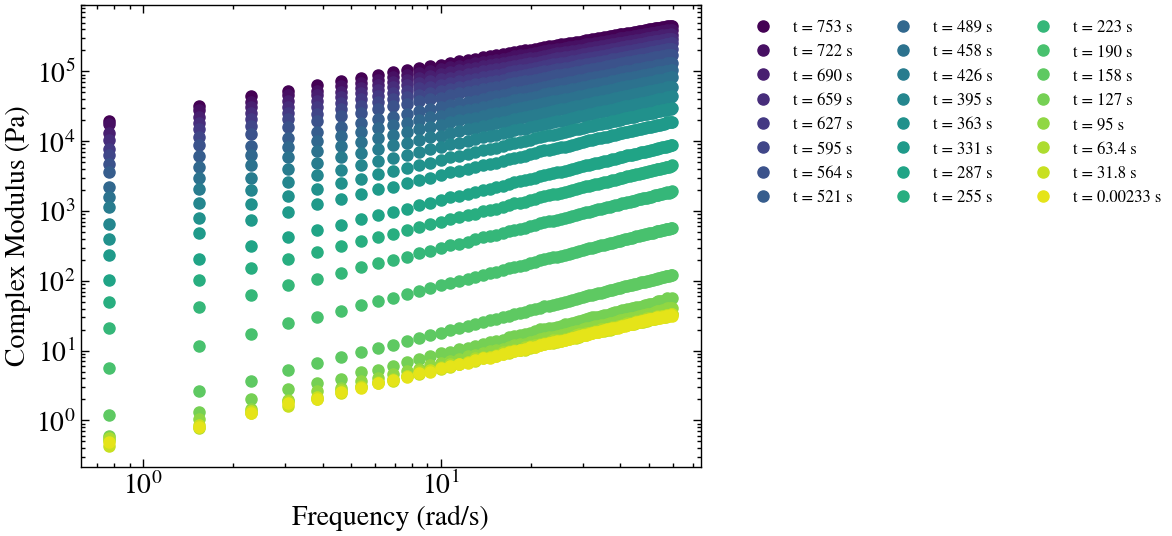

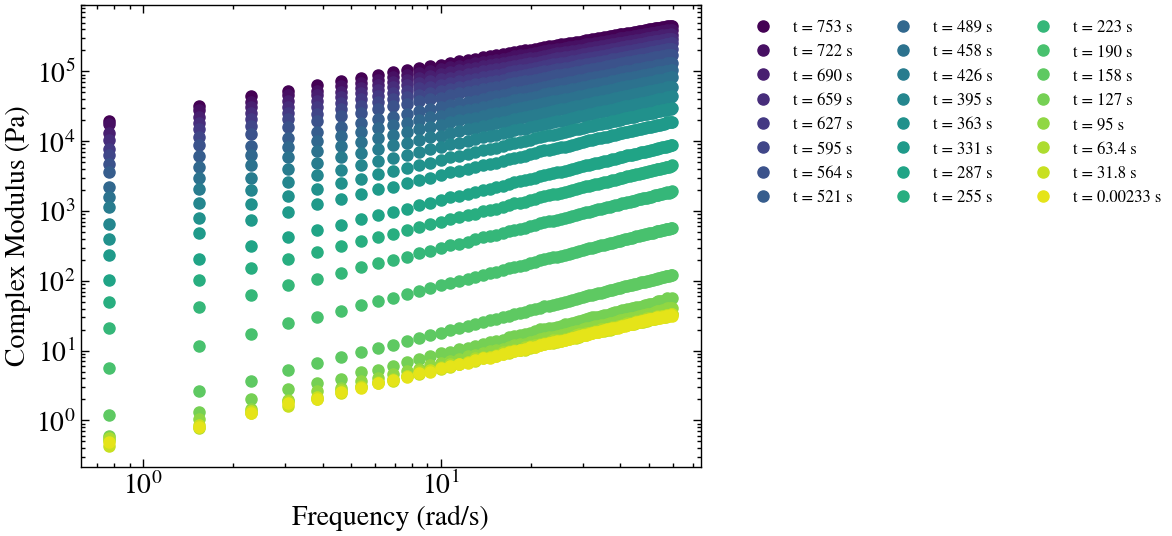

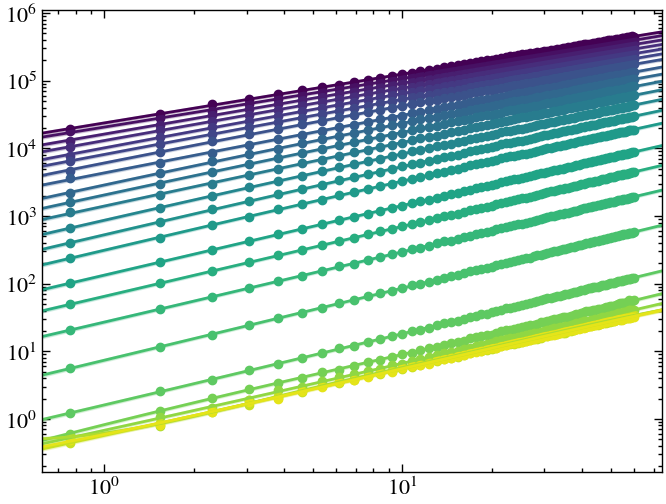

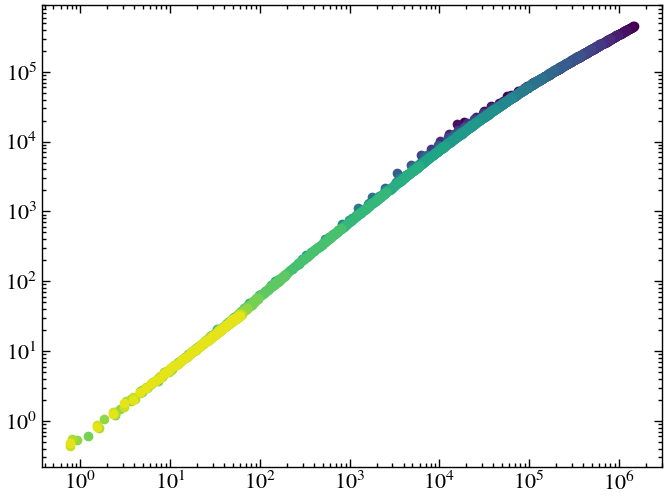

In [7]:
fig1, ax1, fig2, ax2, fig3, ax3 = mastercurve_complex_modulus.plot(
    colormap=plt.cm.viridis,
)

# Set figure size
fig1.set_size_inches(8, 6)

# Read the physical units straight from the OWChirp-processed dataset so
# the labels stay in sync with whatever unit is stored on the moduli
# (Pa for OWChirp-derived moduli, rad/s for angular frequency).
omega_unit = get_unit(experiment_owchirp, "angular frequency")
modulus_unit = get_unit(experiment_owchirp, "complex modulus")

# Set x and y labels
ax1.set_xlabel(rf"Frequency{unit_suffix(omega_unit)}", fontsize = 20)
ax1.set_ylabel(rf"Complex Modulus{unit_suffix(modulus_unit)}", fontsize = 20)

# Increase markersize for each line in ax1
for line in ax1.get_lines():
    line.set_markersize(8) 

# Set font size for x and y tick labels on ax1
ax1.tick_params(axis='x', labelsize=20)  # For x-axis ticks
ax1.tick_params(axis='y', labelsize=20)  # For y-axis ticks

# Format the legend
handles, labels = ax1.get_legend_handles_labels()
formatted_labels = ['t = {:.3g} s'.format(float(label)) for label in labels]
ax1.legend(handles, formatted_labels, fontsize=12, ncol=3, bbox_to_anchor=(1.05, 1), loc='upper left')

fig1

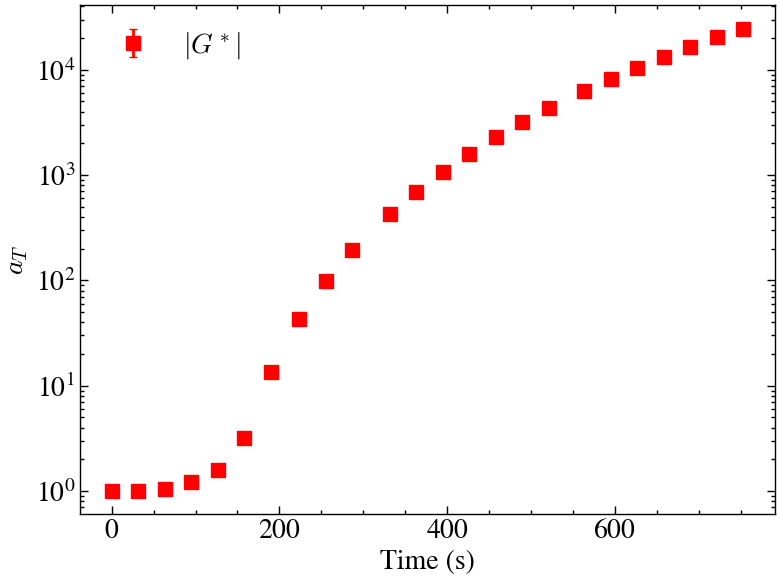

In [8]:
states = mastercurve_complex_modulus.states  # Assuming this is applicable for all

plt.figure(figsize=(8, 6))

plt.errorbar(states, a_complex, yerr=a_complex_uncertainties, fmt='rs', label="$|G^*|$", markersize=10, linestyle='none', capsize=3)

plt.xlabel("Time (s)", fontsize=20)
plt.ylabel("$a_T$", fontsize=20)
plt.xscale('linear')  
plt.yscale('log')
plt.tick_params(axis='x', labelsize=20)
plt.tick_params(axis='y', labelsize=20)
plt.legend(fontsize=20, loc='best', frameon=False, ncol=2)

plt.tight_layout()
plt.show()
